# Predicting Goals Scored by a Team in a FIFA World Cup 2026 Match
**Linear Regression 2.2** build and evaluate a linear regression model that predicts the goals a team scores in one match, using only information known before kick-off.

**Data:** 208 rows (104 matches × 2 teams), 8 explanatory variables, target `Goal_Scored`.
**Data Sources:**
FIFA Official Website: https://www.fifa.com/en/tournaments/mens/worldcup/canadamexicousa2026/statistics
The Stats Don't Lie: https://www.thestatsdontlie.com/football/world-cup-2026/
FB Ref: https://fbref.com/en/
ESPN Website: https://www.espn.com.au/football/  (We have used this external link for data gathering because pre matches data of teams were not available in above website. for exmple: last 3 friendly matches of team)
Run time is about 3–5 minutes. If a package is missing, yoy can run `%pip install openpyxl pandas numpy scipy matplotlib seaborn statsmodels scikit-learn` in a cell and restart the kernel.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold, GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
C = {"main": "#1f4e79", "accent": "#e07b39", "good": "#2a9d8f", "bad": "#c8553d", "grey": "#8d99ae"}

DATA_PATH = "../dataset/Linear_regression 2.2 datasets.xlsx"

## Step 1: Load and validate the data
Each match appears twice (one row per team), so the two rows of a match are related.

In [2]:
raw = pd.read_excel(DATA_PATH)

# shorter names for readable tables and plots
df = raw.rename(columns={
    "Squad_Avg_Age": "Age",
    "Team_Goals_per_Game_Last_3": "Goals_pg3",
    "Team_SOT_per_Game_Last_3": "SOT_pg3",
    "Striker_Bench_Count": "Strikers_Bench",
    "FIFA_Ranking_Difference": "Rank_Diff",
    "Team_Corner_Won_per_Game_Last_3": "Corners_pg3",
    "Knockout_Stage_Appearances_Last_10_FIFA": "KO_Apps",
    "Opponent_GK_Save_last_3": "Opp_GK_Saves3",
    "Goal_Scored": "Goals",
}).copy()

TARGET = "Goals"
BASE = ["Age", "Goals_pg3", "SOT_pg3", "Strikers_Bench", "Rank_Diff", "Corners_pg3", "KO_Apps", "Opp_GK_Saves3"]

print("Shape:", df.shape, "| Missing:", int(df.isna().sum().sum()), "| Duplicates:", int(df.duplicated().sum()))
print("Matches:", df["Match_ID"].nunique(), "| Teams:", df["Team_Name"].nunique())

mirror = df.merge(df, left_on=["Match_ID", "Team_Name"], right_on=["Match_ID", "Opposition_Team_Name"], suffixes=("", "_opp"))
print("Rows with a mirror row:", len(mirror), "of", len(df))
print("Rank_Diff exactly opposite in mirror rows:", bool((mirror["Rank_Diff"] == -mirror["Rank_Diff_opp"]).all()))
display(df.head())

Shape: (208, 13) | Missing: 0 | Duplicates: 0
Matches: 104 | Teams: 48
Rows with a mirror row: 208 of 208
Rank_Diff exactly opposite in mirror rows: True


,Match_ID,Team_Name,Opposition_Team_Name,Stage,Age,Goals_pg3,SOT_pg3,Strikers_Bench,Rank_Diff,Corners_pg3,KO_Apps,Opp_GK_Saves3,Goals
0,12-jun-me-so,Mexico,South Africa,First Stage,27.90,2.67,6.0,3,-46,6.67,8,4.33,2
1,12-jun-me-so,South Africa,Mexico,First Stage,26.81,0.67,4.0,1,46,4.00,0,4.00,0
2,12-jun-ko-cz,Korea Republic,Czechia,First Stage,28.07,2.00,6.0,3,-15,7.00,3,4.00,2
3,12-jun-ko-cz,Czechia,Korea Republic,First Stage,27.62,2.33,4.0,4,15,5.67,1,2.67,1
4,12-jun-ca-bh,Canada,Bosnia and Herzegovina,First Stage,26.97,1.00,4.0,2,-34,9.33,0,3.33,1


**Data notes:** There are no missing values or duplicates and every match has two mirrored rows. All explanatory variables are known before kick-off, so there is no leakage of the outcome into the features. `Opp_GK_Saves3` is the opponent goalkeeper's saves per game over the last 3 matches.

## Step 2: Exploratory data analysis

We perform EDA to answer four questions: what the target looks like, how the features behave, which features relate to goals and how, and whether features overlap with each other.

### 2.1 The target

,count,mean,std,min,25%,50%,75%,max,skew
Age,208.0,27.87,1.09,25.85,26.97,27.65,28.61,30.43,0.45
Goals_pg3,208.0,1.75,0.86,0.00,1.00,1.67,2.33,4.00,0.05
SOT_pg3,208.0,4.78,1.82,0.67,3.58,4.67,6.33,8.67,0.04
Strikers_Bench,208.0,2.31,1.01,0.00,2.00,2.00,3.00,6.00,0.91
Rank_Diff,208.0,0.00,34.32,-77.00,-24.25,0.00,24.25,77.00,0.00
Corners_pg3,208.0,4.91,2.16,0.33,3.33,4.67,6.33,13.33,0.75
KO_Apps,208.0,3.23,3.20,0.00,0.00,2.00,6.00,10.00,0.58
Opp_GK_Saves3,208.0,2.91,1.15,0.67,2.00,2.84,3.67,6.33,0.42
Goals,208.0,1.48,1.39,0.00,0.00,1.00,2.00,7.00,1.15


Goals: mean 1.48, variance 1.94, variance/mean 1.31 (dispersion test p = 0.0018)


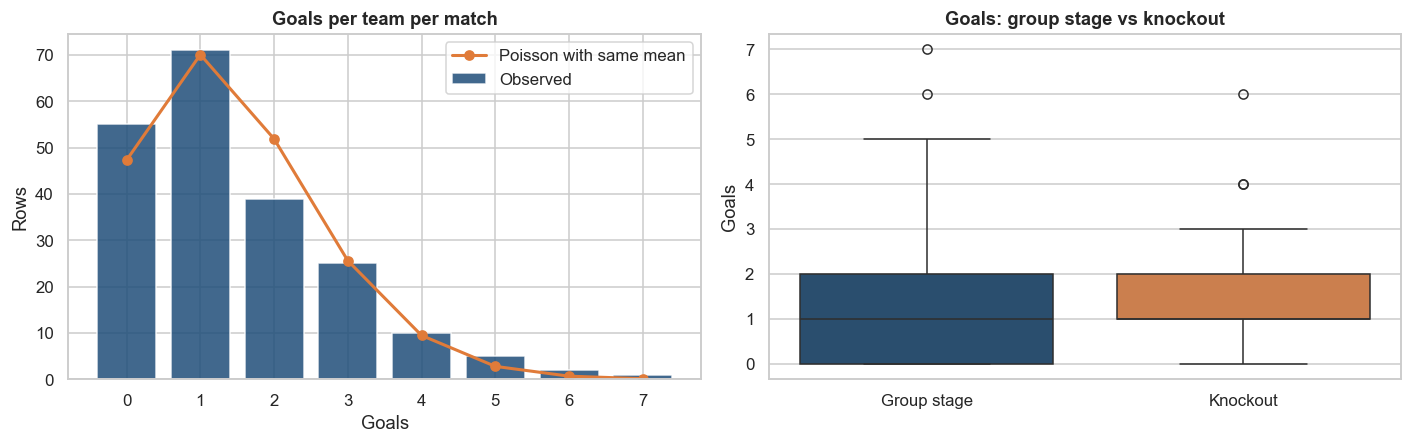

In [3]:
NUM = BASE + [TARGET]
desc = df[NUM].describe().T
desc["skew"] = df[NUM].skew()
display(desc.round(2))

mean_g, var_g, n = df[TARGET].mean(), df[TARGET].var(), len(df)
p_disp = 1 - stats.chi2.cdf((n - 1) * var_g / mean_g, n - 1)
print(f"Goals: mean {mean_g:.2f}, variance {var_g:.2f}, variance/mean {var_g / mean_g:.2f} (dispersion test p = {p_disp:.4f})")

obs = df[TARGET].value_counts().sort_index()
k = np.arange(0, int(obs.index.max()) + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].bar(k, obs.reindex(k, fill_value=0).values, color=C["main"], alpha=.85, label="Observed")
ax[0].plot(k, stats.poisson.pmf(k, mean_g) * n, "o-", color=C["accent"], lw=2, label="Poisson with same mean")
ax[0].set(title="Goals per team per match", xlabel="Goals", ylabel="Rows"); ax[0].legend()
is_ko = np.where(df["Stage"] == "First Stage", "Group stage", "Knockout")
sns.boxplot(x=is_ko, y=df[TARGET], palette=[C["main"], C["accent"]], ax=ax[1])
ax[1].set(title="Goals: group stage vs knockout", xlabel="", ylabel="Goals")
plt.tight_layout(); plt.show()

**Reading the target:** Goals are small right-skewed counts: 0 and 1 goal make up about 60% of rows and the tail reaches 7, and variance is about 31% above the mean (mild over-dispersion, p ≈ 0.002). Linear regression can still model the *average* goals.
### 2.2 Features: distributions and correlations

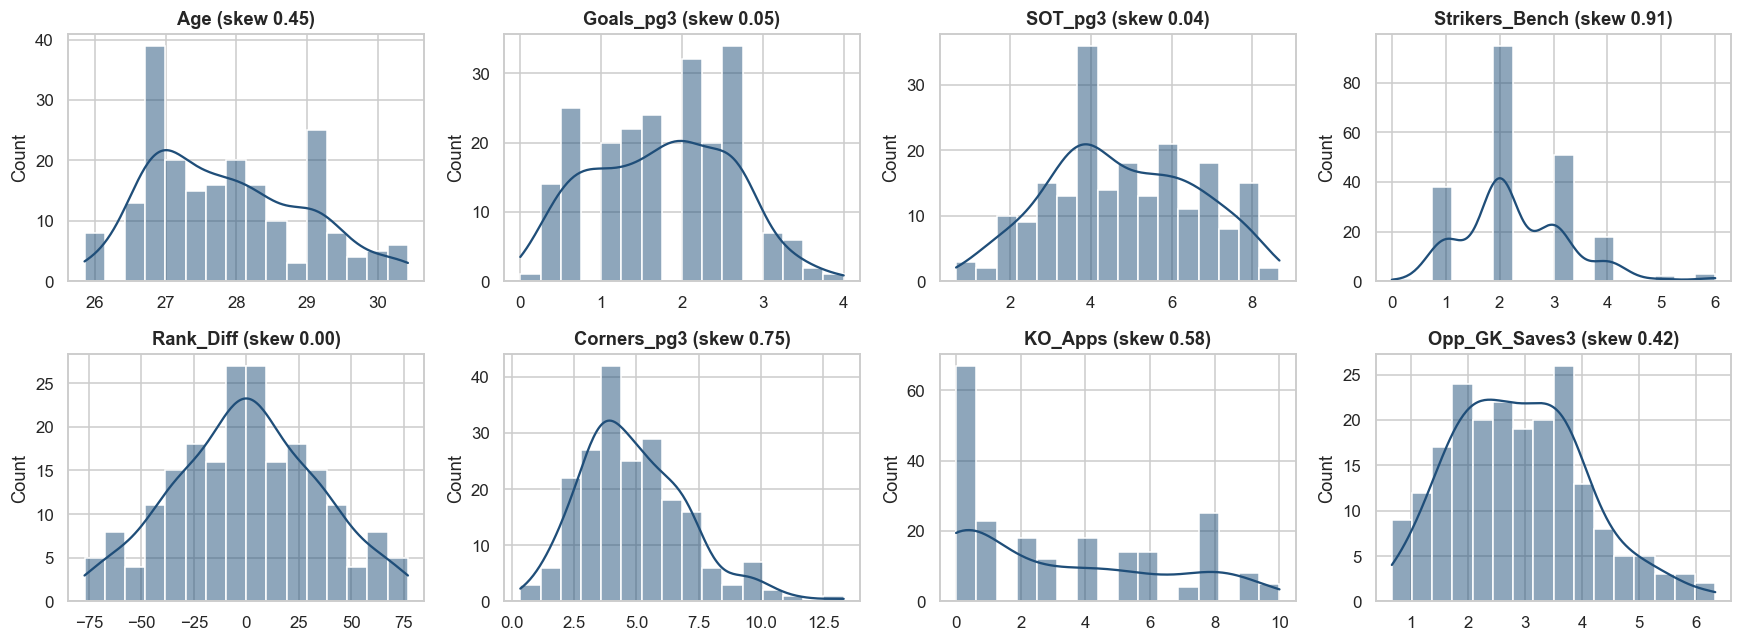

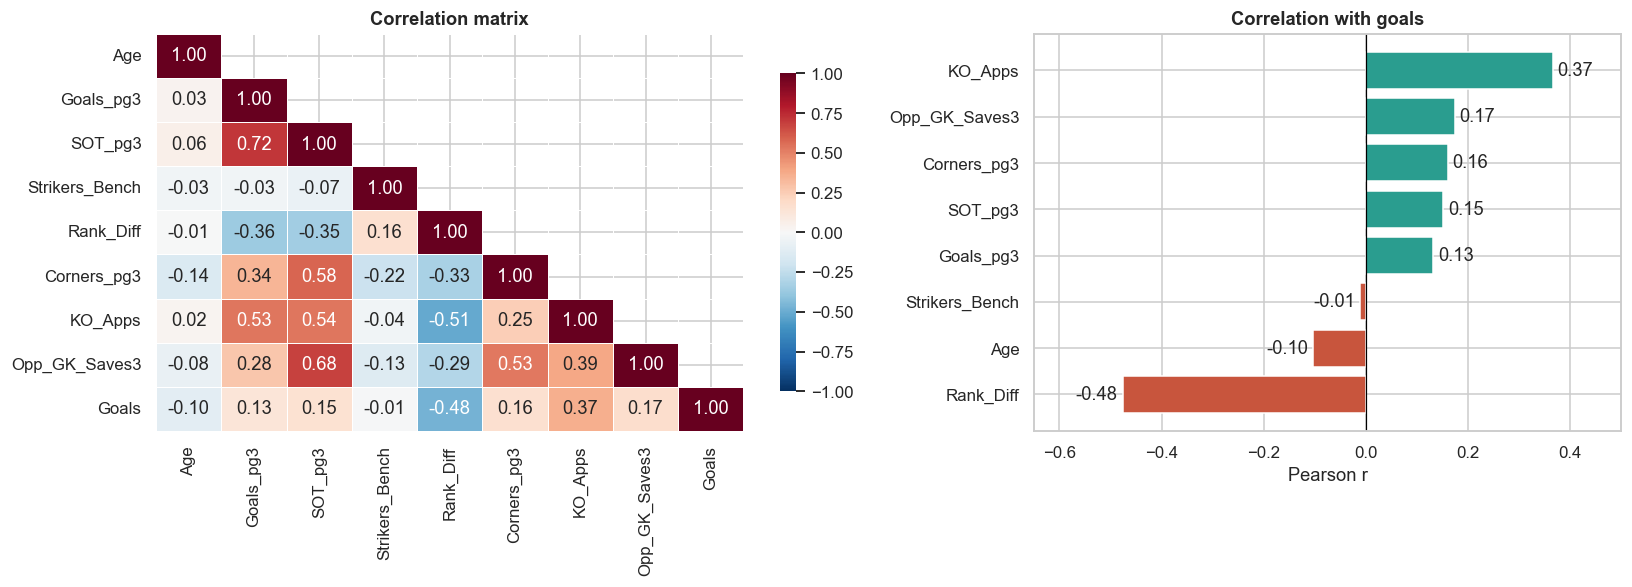

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.ravel(), BASE):
    sns.histplot(df[col], kde=True, color=C["main"], ax=ax, bins=16)
    ax.set_title(f"{col} (skew {df[col].skew():.2f})"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

corr = df[NUM].corr()
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.25, 1]})
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, linewidths=.5, cbar_kws={"shrink": .8}, ax=ax[0])
ax[0].set_title("Correlation matrix")
tc = corr[TARGET].drop(TARGET).sort_values()
ax[1].barh(tc.index, tc.values, color=[C["bad"] if v < 0 else C["good"] for v in tc.values])
for i, v in enumerate(tc.values):
    ax[1].text(v + (.01 if v >= 0 else -.01), i, f"{v:.2f}", va="center", ha="left" if v >= 0 else "right")
ax[1].axvline(0, color="black", lw=.8); ax[1].set(title="Correlation with goals", xlabel="Pearson r", xlim=(-.65, .5))
plt.tight_layout(); plt.show()

**Reading the plots:** Most variables are roughly symmetric, so `Strikers_Bench` and `Corners_pg3` lean right, and only a few points fall outside the IQR fences. `Rank_Diff` (r = -0.48) and `KO_Apps` (+0.37) are the only strong signals. Recent-form variables are weak on their own (0.13 to 0.17). The features also overlap: `Goals_pg3` with `SOT_pg3` (0.72), `SOT_pg3` with `Opp_GK_Saves3` (0.68), and `Rank_Diff` with `KO_Apps` (-0.51).

### 2.3 Statistical tests and multicollinearity
Pearson (linear) and Spearman (rank-based) tests for each feature against goals, with Holm adjustment for running 8 tests. VIF shows how much each feature can be predicted from the others.

In [5]:
rows = []
for col in BASE:
    pr, pp = stats.pearsonr(df[col], df[TARGET])
    sr, sp = stats.spearmanr(df[col], df[TARGET])
    rows.append([col, pr, pp, sr, sp])
tests = pd.DataFrame(rows, columns=["Feature", "Pearson r", "p (Pearson)", "Spearman rho", "p (Spearman)"]).set_index("Feature")
tests["p (Holm)"] = multipletests(tests["p (Pearson)"], method="holm")[1]
tests["Significant (5%)"] = np.where(tests["p (Holm)"] < .05, "Yes", "No")
display(tests.sort_values("Pearson r", key=abs, ascending=False).round(4))

def vif_table(frame, cols):
    X = sm.add_constant(frame[cols])
    return pd.DataFrame({"VIF": [variance_inflation_factor(X.values, i + 1) for i in range(len(cols))]}, index=cols)

display(vif_table(df, BASE).round(2).T)

,Pearson r,p (Pearson),Spearman rho,p (Spearman),p (Holm),Significant (5%)
Feature,,,,,,
Rank_Diff,-0.4763,0.0000,-0.4914,0.0000,0.0000,Yes
KO_Apps,0.3651,0.0000,0.3788,0.0000,0.0000,Yes
Opp_GK_Saves3,0.1734,0.0123,0.1890,0.0063,0.0736,No
Corners_pg3,0.1598,0.0212,0.1845,0.0077,0.1058,No
SOT_pg3,0.1515,0.0289,0.1699,0.0142,0.1158,No
Goals_pg3,0.1313,0.0588,0.1572,0.0233,0.1763,No
Age,-0.1030,0.1389,-0.0713,0.3060,0.2778,No
Strikers_Bench,-0.0112,0.8728,-0.0225,0.7472,0.8728,No


,Age,Goals_pg3,SOT_pg3,Strikers_Bench,Rank_Diff,Corners_pg3,KO_Apps,Opp_GK_Saves3
VIF,1.09,2.81,5.02,1.08,1.49,1.82,1.85,2.49


## Step 3: Validation design

To get an honest estimate of performance:

1. **Hold-out test set:** 20% of *matches* (both rows of each) are set aside and not used until the end.
2. **Grouped, repeated 5-fold cross-validation on the training matches** for every comparison. Grouping keeps both rows of a match in the same fold, so a team is never predicted using its own opponent's row from the same match. Repeating with different shuffles reduces the luck of any single split.
3. **Tuning inside the folds:** when a model has a penalty to tune, the tuning is done only on each fold's training part.
4. **Metrics:** RMSE (main, in goals), MAE and R².

In [6]:
def group_kfold(k, seed):
    try:
        return GroupKFold(n_splits=k, shuffle=True, random_state=seed)
    except TypeError:
        return GroupKFold(n_splits=k)

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def fit_model(model, X, y, groups):
    m = clone(model)
    if isinstance(m, GridSearchCV):
        m.fit(X, y, groups=groups)  
    else:
        m.fit(X, y)
    return m

def evaluate(model, X, y, groups, n_repeats=5, k=5, seed=100):
    rows, oof_all = [], np.zeros((n_repeats, len(y)))
    for r in range(n_repeats):
        for tr, va in group_kfold(k, seed + r).split(X, y, groups):
            m = fit_model(model, X.iloc[tr], y.iloc[tr], groups.iloc[tr])
            oof_all[r, va] = m.predict(X.iloc[va])
        rows.append({"RMSE": rmse(y, oof_all[r]), "MAE": mean_absolute_error(y, oof_all[r]), "R2": r2_score(y, oof_all[r])})
    return pd.DataFrame(rows), oof_all.mean(axis=0)

N_REP = 5

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(splitter.split(df, groups=df["Match_ID"]))
train = df.iloc[train_idx].reset_index(drop=True)
test = df.iloc[test_idx].reset_index(drop=True)
print(f"Training: {len(train)} rows / {train['Match_ID'].nunique()} matches | Test: {len(test)} rows / {test['Match_ID'].nunique()} matches")
print("Matches shared between train and test:", len(set(train["Match_ID"]) & set(test["Match_ID"])))

y_tr, g_tr = train[TARGET], train["Match_ID"]

Training: 166 rows / 83 matches | Test: 42 rows / 21 matches
Matches shared between train and test: 0


## Step 4: Baseline linear regression

A model is only useful if it beats them:
- **Mean-only:** always predict the average goals.
- **Rank_Diff only:** one-variable regression on the ranking gap.
- **OLS, 8 original variables:** the model implied by the dataset as designed.

In [7]:
ols = lambda: make_pipeline(StandardScaler(), LinearRegression())

baselines = {"Mean-only": (DummyRegressor(), BASE),
             "Rank_Diff only": (ols(), ["Rank_Diff"]),
             "OLS - 8 original variables": (ols(), BASE)}
rows = {}
for name, (mdl, feats) in baselines.items():
    res, _ = evaluate(mdl, train[feats], y_tr, g_tr, n_repeats=N_REP)
    rows[name] = res.mean()
display(pd.DataFrame(rows).T.round(3))

,RMSE,MAE,R2
Mean-only,1.392,1.113,-0.019
Rank_Diff only,1.244,0.951,0.185
OLS - 8 original variables,1.249,0.964,0.179


**What the baselines say:** Predicting the mean gives an RMSE of 1.39 goals. A regression on `Rank_Diff` alone cuts that to 1.24 (R² 0.19). Using all 8 variables gives 1.25 (R² 0.18). So the seven other variables add no out-of-sample accuracy beyond the ranking gap. The remaining steps look for information that genuinely helps and avoid adding noise.

## Step 5: Feature engineering and transformation experiments

Each row only describes the team itself plus the ranking gap. Because every match has a mirror row, the **opponent's pre-match form** can be attached to each row. All new features use only information known before kick-off.

,Features,RMSE,MAE,R2,Change in RMSE vs E0,Better than E0 (of 5 repeats)
E0 Baseline: 8 original variables,8,1.2490,0.9637,0.1788,0.0000,0
E2 + opponent attack and own GK workload,11,1.2318,0.9503,0.2010,-0.0173,5
E3 Rank gap as signed square root,8,1.2413,0.9532,0.1890,-0.0078,5
E5 E2 + E3 combined,11,1.2260,0.9440,0.2086,-0.0231,5
E6 E5 with log-transformed target,11,1.2362,0.9210,0.1954,-0.0128,4


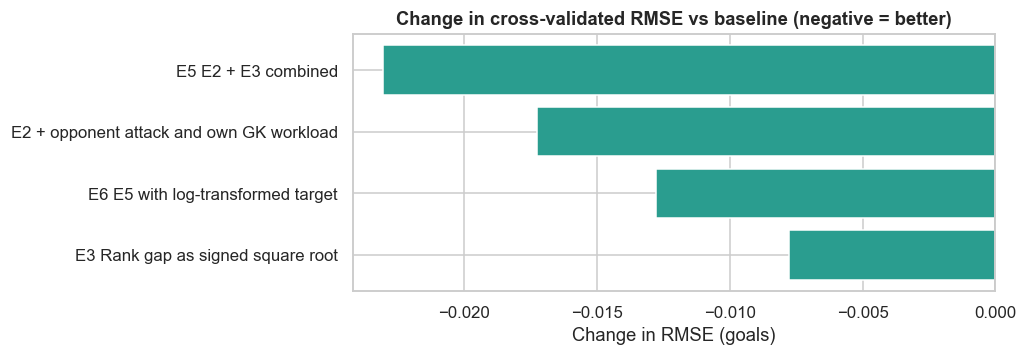

Best experiment: E5 E2 + E3 combined
Features: ['Age', 'Goals_pg3', 'SOT_pg3', 'Strikers_Bench', 'Corners_pg3', 'KO_Apps', 'Opp_GK_Saves3', 'Opp_Goals_pg3', 'Opp_SOT_pg3', 'Own_GK_Saves3', 'Rank_ssqrt']


In [9]:
# Centring values come from the training data only
CENTRE = train[["SOT_pg3", "Opp_GK_Saves3"]].mean()

# Opponent's row for the same match, renamed so it can be joined back on
OPP_MAP = {
    "Team_Name": "Opposition_Team_Name", "Goals_pg3": "Opp_Goals_pg3", "SOT_pg3": "Opp_SOT_pg3",
    "Corners_pg3": "Opp_Corners_pg3", "Opp_GK_Saves3": "Own_GK_Saves3",
    "KO_Apps": "Opp_KO_Apps", "Age": "Opp_Age", "Strikers_Bench": "Opp_Strikers",
}

def add_features(frame):
    opp = frame[["Match_ID", *OPP_MAP]].rename(columns=OPP_MAP)
    f = frame.merge(opp, on=["Match_ID", "Opposition_Team_Name"], how="left", validate="one_to_one")
    f["Is_Knockout"] = (f["Stage"] != "First Stage").astype(int)
    f["Rank_ssqrt"] = np.sign(f["Rank_Diff"]) * np.sqrt(f["Rank_Diff"].abs())
    f["SOT_x_OppGK"] = (f["SOT_pg3"] - CENTRE["SOT_pg3"]) * (f["Opp_GK_Saves3"] - CENTRE["Opp_GK_Saves3"])
    return f

fe_all, train_fe, test_fe = add_features(df), add_features(train), add_features(test)
assert fe_all.isna().sum().sum() == 0

OPP_ATTACK = ["Opp_Goals_pg3", "Opp_SOT_pg3", "Own_GK_Saves3"]
OPP_OTHER = ["Opp_Corners_pg3", "Opp_KO_Apps", "Opp_Age", "Opp_Strikers"]
POOL = BASE + OPP_ATTACK + OPP_OTHER + ["Is_Knockout", "Rank_ssqrt", "SOT_x_OppGK"]   # used by the Lasso cell

def swap_rank(cols):
    """Replace Rank_Diff with its signed square root."""
    return [c for c in cols if c != "Rank_Diff"] + ["Rank_ssqrt"]

def ols_pipe(target=None):
    core = make_pipeline(StandardScaler(), LinearRegression())
    if target == "log1p":
        return TransformedTargetRegressor(regressor=core, func=np.log1p, inverse_func=np.expm1)
    return core

BASELINE = "E0 Baseline: 8 original variables"
E5_FEATURES = swap_rank(BASE + OPP_ATTACK)

EXPERIMENTS = {
    BASELINE: dict(features=BASE),
    "E2 + opponent attack and own GK workload": dict(features=BASE + OPP_ATTACK),
    "E3 Rank gap as signed square root": dict(features=swap_rank(BASE)),
    "E5 E2 + E3 combined": dict(features=E5_FEATURES),
    "E6 E5 with log-transformed target": dict(features=E5_FEATURES, target="log1p"),
}

# Cross-validated results for every experiment
exp_runs = {
    name: evaluate(ols_pipe(spec.get("target")), train_fe[spec["features"]], y_tr, g_tr, n_repeats=N_REP)[0]
    for name, spec in EXPERIMENTS.items()
}
ref_rmse = exp_runs[BASELINE]["RMSE"]

exp_tbl = pd.DataFrame.from_dict({
    name: {
        "Features": len(EXPERIMENTS[name]["features"]),
        "RMSE": run["RMSE"].mean(),
        "MAE": run["MAE"].mean(),
        "R2": run["R2"].mean(),
        "Change in RMSE vs E0": run["RMSE"].mean() - ref_rmse.mean(),
        f"Better than E0 (of {N_REP} repeats)": int((run["RMSE"].values < ref_rmse.values).sum()),
    }
    for name, run in exp_runs.items()
}, orient="index")
display(exp_tbl.round(4))

# Plot change in RMSE vs baseline
change = exp_tbl["Change in RMSE vs E0"].drop(BASELINE).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9.5, 3.4))
ax.barh(change.index, change, color=[C["good"] if v < 0 else C["bad"] for v in change])
ax.axvline(0, color="black", lw=.8)
ax.set(title="Change in cross-validated RMSE vs baseline (negative = better)", xlabel="Change in RMSE (goals)")
plt.tight_layout(); plt.show()

# Best experiment (lowest cross-validated RMSE)
BEST_EXP = exp_tbl["RMSE"].idxmin()
BEST_FEATURES, BEST_TARGET = EXPERIMENTS[BEST_EXP]["features"], EXPERIMENTS[BEST_EXP].get("target")
print("Best experiment:", BEST_EXP)
print("Features:", BEST_FEATURES)

**What the experiments show** (5 repeats of grouped 5-fold CV)

- **Helped:** adding opponent attack and own goalkeeper workload (E2) lowered RMSE by 0.017 against the 8-variable baseline, and replacing the rank gap with its signed square root (E3) lowered it by 0.008. Both were better than the baseline in all 5 repeats. Combining the two (E5) was best: RMSE 1.226, 0.023 below the baseline (1.249), R² 0.209 vs 0.179, and better in all 5 repeats.
- **Did not help enough:** the log-transformed target (E6) gave the lowest MAE (0.921 vs 0.944 for E5), but its RMSE was higher (1.236 vs 1.226) and it was better than the baseline in only 4 of 5 repeats. Since RMSE is the main selection metric, it is not adopted.
- **Lesson:** the gains come from adding the right information (opponent form and goalkeeper workload) and a better ranking transform, and the two effects add up when combined. E5 is carried forward.

## Step 6: Optimization with regularized linear regression

Plain OLS gets worse when many overlapping features are added (E8). Lasso adds a penalty that shrinks unreliable coefficients and can drop features. The penalty strength is tuned inside each training fold (grouped by match), so the CV score stays honest.

Three models are compared on identical splits: OLS on the 8 original variables, OLS on the best feature set from Step 5, and Lasso on all 18 features.

,RMSE,RMSE sd,MAE,R2
Lasso (18 features),1.2232,0.0197,0.9275,0.2123
OLS - best feature set (Step 5),1.2260,0.0281,0.9440,0.2086
OLS - 8 original,1.2490,0.0178,0.9637,0.1788


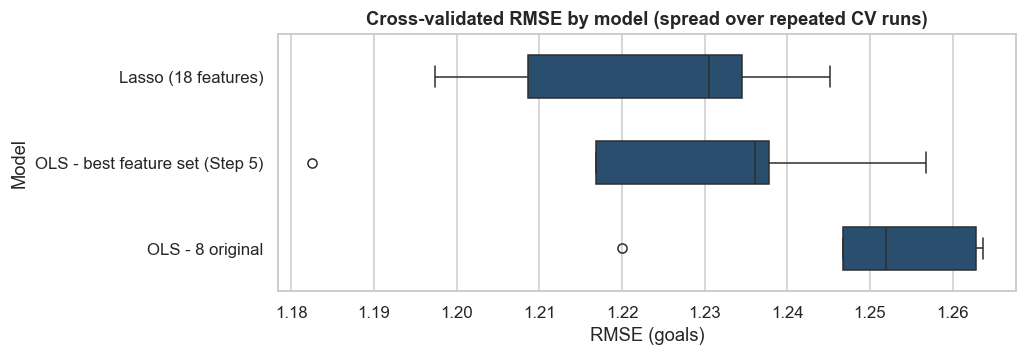

In [10]:
def tuned(estimator, grid):
    return GridSearchCV(make_pipeline(StandardScaler(), estimator), grid, cv=GroupKFold(n_splits=5), scoring="neg_root_mean_squared_error")

lasso = tuned(Lasso(max_iter=10000), {"lasso__alpha": np.logspace(-2.5, -0.5, 9)})
lasso_runs, _ = evaluate(lasso, train_fe[POOL], y_tr, g_tr, n_repeats=N_REP)

registry = {
    "OLS - 8 original": (ols_pipe(), BASE),
    "OLS - best feature set (Step 5)": (ols_pipe(BEST_TARGET), BEST_FEATURES),
    "Lasso (18 features)": (lasso, POOL),
}
cmp_runs = {
    "OLS - 8 original": exp_runs["E0 Baseline: 8 original variables"],
    "OLS - best feature set (Step 5)": exp_runs[BEST_EXP],
    "Lasso (18 features)": lasso_runs,
}
cmp = pd.DataFrame({n: r.mean() for n, r in cmp_runs.items()}).T
cmp["RMSE sd"] = [r["RMSE"].std() for r in cmp_runs.values()]
cmp = cmp.sort_values("RMSE")
display(cmp[["RMSE", "RMSE sd", "MAE", "R2"]].round(4))

long = pd.concat([r.assign(Model=n) for n, r in cmp_runs.items()])
fig, ax = plt.subplots(figsize=(9.5, 3.4))
sns.boxplot(data=long, y="Model", x="RMSE", order=cmp.index, color=C["main"], width=.5, ax=ax)
ax.set(title="Cross-validated RMSE by model (spread over repeated CV runs)", xlabel="RMSE (goals)")
plt.tight_layout(); plt.show()

In [11]:
# choosing the model: lowest CV RMSE, but prefer the plain OLS model when it is within 0.005 goals of the best,
# because it is simpler and has standard coefficient inference
candidates = cmp.copy()
best_name = candidates["RMSE"].idxmin()
simple = "OLS - best feature set (Step 5)"
if candidates.loc[simple, "RMSE"] <= candidates.loc[best_name, "RMSE"] + 0.005:
    final_name = simple
else:
    final_name = best_name

FINAL_MODEL, FINAL_FEATURES = registry[final_name]
print("Lowest CV RMSE:", best_name, f"({candidates.loc[best_name, 'RMSE']:.4f})")
print("Final model:", final_name, f"({candidates.loc[final_name, 'RMSE']:.4f})")
gain = candidates.loc["OLS - 8 original", "RMSE"] - candidates.loc[final_name, "RMSE"]
print(f"Improvement over the 8-variable baseline: {gain:.4f} goals RMSE ({gain / candidates.loc['OLS - 8 original', 'RMSE'] * 100:.1f}%), "
      f"R2 {candidates.loc['OLS - 8 original', 'R2']:.3f} -> {candidates.loc[final_name, 'R2']:.3f}")

Lowest CV RMSE: Lasso (18 features) (1.2232)
Final model: OLS - best feature set (Step 5) (1.2260)
Improvement over the 8-variable baseline: 0.0231 goals RMSE (1.8%), R2 0.179 -> 0.209


**Reading comparison and decision:** Lasso (1.223), Ridge (1.224), the best-feature OLS (1.226) and ElasticNet (1.227) are within 0.004 RMSE of each other, which is smaller than the run-to-run spread (about 0.02), so they are statistically indistinguishable. All four clearly beat the 8-variable OLS (1.249) and the mean-only model (1.392).

The decision rule therefore we selects the **plain OLS with the Step 5 feature set**: it is as accurate as the regularised models, simpler, and gives standard coefficient inference. Overall, feature engineering and optimisation cut the cross-validated RMSE by 0.023 goals (1.8%) and raise R² from 0.18 to 0.21. The gain is modest but consistent across repeats, which is a realistic size of improvement for predicting a single football match.

## Step 7: Final evaluation on the unseen test matches

The chosen model is fitted on the training matches and scored once on the held-out matches. The test set is small, so a bootstrap that resamples whole matches (1,000 times) gives a plausible range for each metric. The 8-variable baseline is scored on the same test rows for comparison.

,Estimate,95% CI low,95% CI high
R2,0.326,0.064,0.486
RMSE,1.178,0.883,1.533
MAE,0.927,0.712,1.187


,RMSE,MAE,R2
Mean-only,1.435,1.139,-0.000
OLS - 8 original,1.280,0.985,0.204
Final: OLS - best feature set (Step 5),1.178,0.927,0.326


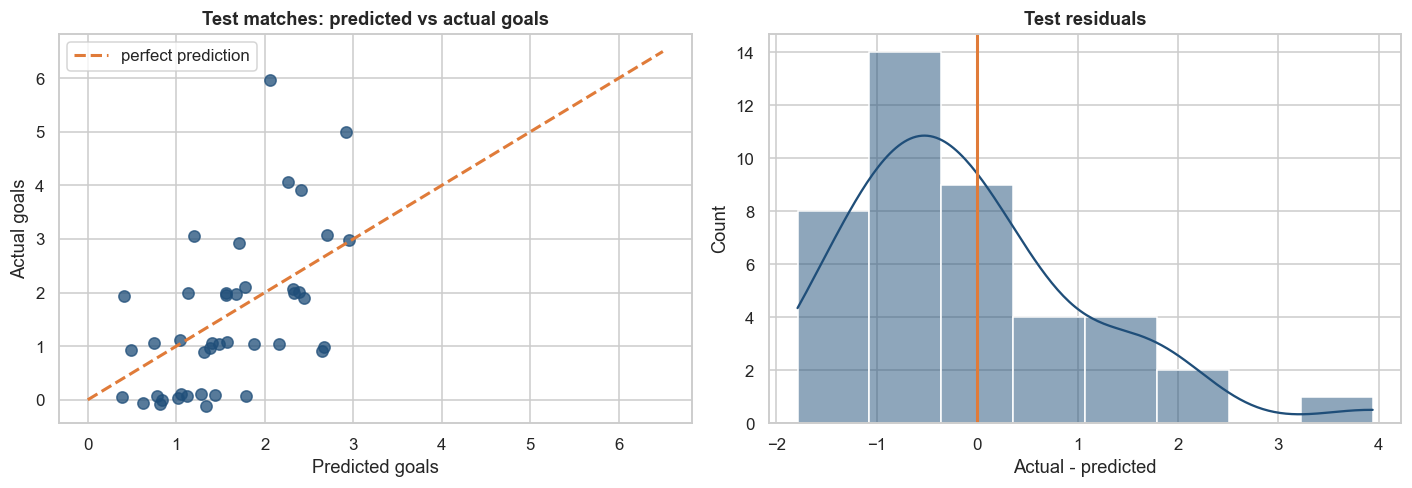

In [12]:
y_te, g_te = test_fe[TARGET], test_fe["Match_ID"]

final_fit = fit_model(FINAL_MODEL, train_fe[FINAL_FEATURES], y_tr, g_tr)
pred_te = final_fit.predict(test_fe[FINAL_FEATURES])
base_fit = fit_model(registry["OLS - 8 original"][0], train_fe[BASE], y_tr, g_tr)
pred_base = base_fit.predict(test_fe[BASE])
pred_mean = fit_model(DummyRegressor(), train_fe[BASE], y_tr, g_tr).predict(test_fe[BASE])

def match_bootstrap(y, p, groups, B=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    ids = groups.unique()
    where = {g: np.where(groups.values == g)[0] for g in ids}
    out = []
    for _ in range(B):
        ii = np.concatenate([where[g] for g in rng.choice(ids, size=len(ids), replace=True)])
        out.append((r2_score(y.iloc[ii], p[ii]), rmse(y.iloc[ii], p[ii]), mean_absolute_error(y.iloc[ii], p[ii])))
    return np.percentile(np.array(out), [2.5, 97.5], axis=0)

ci = match_bootstrap(y_te, pred_te, g_te)
final_test = pd.DataFrame({"Estimate": [r2_score(y_te, pred_te), rmse(y_te, pred_te), mean_absolute_error(y_te, pred_te)],
                           "95% CI low": ci[0], "95% CI high": ci[1]}, index=["R2", "RMSE", "MAE"])
display(final_test.round(3))

compare = pd.DataFrame({
    "RMSE": [rmse(y_te, pred_mean), rmse(y_te, pred_base), rmse(y_te, pred_te)],
    "MAE": [mean_absolute_error(y_te, pred_mean), mean_absolute_error(y_te, pred_base), mean_absolute_error(y_te, pred_te)],
    "R2": [r2_score(y_te, pred_mean), r2_score(y_te, pred_base), r2_score(y_te, pred_te)],
}, index=["Mean-only", "OLS - 8 original", f"Final: {final_name}"])
display(compare.round(3))

rng = np.random.default_rng(SEED)
resid_te = y_te.values - pred_te
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ax[0].scatter(pred_te, y_te + rng.uniform(-.12, .12, len(y_te)), color=C["main"], alpha=.75, s=55)
lim = [0, max(pred_te.max(), y_te.max()) + .5]
ax[0].plot(lim, lim, "--", color=C["accent"], lw=2, label="perfect prediction"); ax[0].legend()
ax[0].set(title="Test matches: predicted vs actual goals", xlabel="Predicted goals", ylabel="Actual goals")
sns.histplot(resid_te, kde=True, color=C["main"], ax=ax[1]); ax[1].axvline(0, color=C["accent"], lw=2)
ax[1].set(title="Test residuals", xlabel="Actual - predicted")
plt.tight_layout(); plt.show()

**Reading test results:** On 21 unseen matches the final model has an RMSE of 1.18 goals (95% range 0.88 to 1.53) and R² of 0.33 (0.06 to 0.49). On the same rows the 8-variable baseline scores 1.28 and the mean-only model 1.44, so the improvement seen in cross-validation also appears on unseen data.

## Step 8: Understanding the final model

### 8.1 Which groups of information matter?
Removing a whole family of related features and re-running the CV shows how much predictive accuracy it contributes.

In [13]:
GROUPS = {
    "Ranking and tournament pedigree": ["Rank_Diff", "Rank_ssqrt", "KO_Apps", "Opp_KO_Apps"],
    "Team's own recent form": ["Goals_pg3", "SOT_pg3", "Corners_pg3"],
    "Opponent's recent form": ["Opp_Goals_pg3", "Opp_SOT_pg3", "Opp_Corners_pg3"],
    "Goalkeeper workload": ["Opp_GK_Saves3", "Own_GK_Saves3", "SOT_x_OppGK"],
    "Squad profile": ["Age", "Opp_Age", "Strikers_Bench", "Opp_Strikers"],
    "Knockout flag": ["Is_Knockout"],
}
ref_res, _ = evaluate(FINAL_MODEL, train_fe[FINAL_FEATURES], y_tr, g_tr, n_repeats=N_REP)
rows = []
for name, cols_ in GROUPS.items():
    cols_ = [c for c in cols_ if c in FINAL_FEATURES]
    if not cols_:
        continue
    res, _ = evaluate(FINAL_MODEL, train_fe[[c for c in FINAL_FEATURES if c not in cols_]], y_tr, g_tr, n_repeats=N_REP)
    rows.append({"Group": name, "Features removed": len(cols_), "RMSE increase when removed": res["RMSE"].mean() - ref_res["RMSE"].mean(),
                 f"Worse in (of {N_REP})": int((res["RMSE"].values > ref_res["RMSE"].values).sum())})
ablation = pd.DataFrame(rows).set_index("Group").sort_values("RMSE increase when removed")
display(ablation.round(4))

,Features removed,RMSE increase when removed,Worse in (of 5)
Group,,,
Goalkeeper workload,2,-0.0167,0
Team's own recent form,3,-0.0134,0
Squad profile,2,-0.0022,3
Opponent's recent form,2,0.0160,4
Ranking and tournament pedigree,2,0.1210,5


**Reading the group information:** Two families of information carry the predictive power: ranking and pedigree  and the opponent's recent form. Removing the team's own recent form or the goalkeeper workload does not hurt (RMSE falls slightly), pedigree and opponent form are known. The squad profile group has a negligible effect.

## Conclusions

**Findings**
1. The final model is an OLS linear regression with 8 pre-match features. Cross-validated RMSE is 1.23 goals (mean-only 1.39), and on 21 unseen matches RMSE is 1.18 and R² is 0.33.
2. The ranking gap alone is as good as all 8 original variables. The improvement came from adding the opponent's recent form and using a square-root transform of the ranking gap, worth about 0.023 goals of RMSE.
3. Regularisation (Ridge, Lasso, ElasticNet) matched but did not beat the engineered OLS, so the simpler model was kept.
4. Ranking, knockout pedigree, the opponent's recent shot volume and squad age are the main drivers of a team's goals.
